In [230]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
data=np.load("/home/yuan/code/SeisMoE/data/test/phasenet.npz")
hd=h5py.File(r"/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/waveforms_all_nonoise.hdf5",'r')
f=hd['data']

In [231]:
T=data["T"].tolist()
T

['bucket370$435,:3,:6000',
 'bucket239$91,:3,:6000',
 'bucket212$830,:3,:6000',
 'bucket346$868,:3,:6000',
 'bucket242$688,:3,:6000',
 'bucket202$576,:3,:6000',
 'bucket458$724,:3,:6000',
 'bucket292$665,:3,:6000',
 'bucket328$543,:3,:6000',
 'bucket340$224,:3,:6000',
 'bucket423$244,:3,:6000',
 'bucket388$484,:3,:6000',
 'bucket489$344,:3,:6000',
 'bucket338$843,:3,:6000',
 'bucket480$64,:3,:6000',
 'bucket242$395,:3,:6000',
 'bucket497$560,:3,:6000',
 'bucket419$69,:3,:6000',
 'bucket454$333,:3,:6000',
 'bucket401$937,:3,:6000',
 'bucket381$69,:3,:6000',
 'bucket404$779,:3,:6000',
 'bucket329$606,:3,:6000',
 'bucket402$904,:3,:6000',
 'bucket286$1012,:3,:6000',
 'bucket265$401,:3,:6000',
 'bucket467$22,:3,:6000',
 'bucket457$467,:3,:6000',
 'bucket307$252,:3,:6000',
 'bucket470$380,:3,:6000',
 'bucket352$851,:3,:6000']

In [232]:
trace_name='bucket480$64,:3,:6000'
T=data["T"].tolist()
P=data["P"]
S=data["S"]
N=data["N"]
T_index=T.index(trace_name)
P_data=P[T_index]
S_data=S[T_index]
N_data=N[T_index]

hd_data=f.get(trace_name)[:]

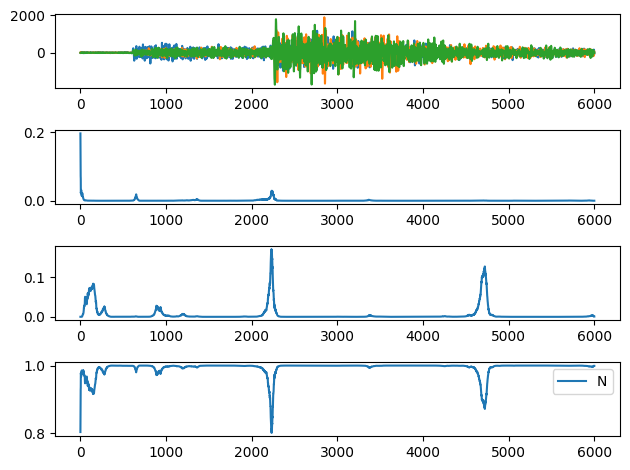

In [233]:
fig,ax=plt.subplots(4,1)

ax[0].plot(hd_data[0,:],label="N")
ax[0].plot(hd_data[1,:],label="H")
ax[0].plot(hd_data[2,:],label="Z")
ax[1].plot(P_data,label="P")
ax[2].plot(S_data,label="S")
ax[3].plot(N_data,label="N")

plt.legend()
plt.tight_layout()
plt.show()


In [239]:
f=h5py.File(r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/waveforms_all_nonoise.hdf5','r')
f=f['data']
fd=f.get("bucket445$710,:3,:6000")[:]


# f=h5py.File(r'/mnt/nn/Code/DATA/STEAD/STEAD.hdf5','r')
# f=f['data']
# fd=f.get("HLPD.HV_20160603195436_EV")[:]

# Phasenet

In [20]:
import pandas as pd
# data=pd.read_csv(r'/home/yuan/code/SeisMoE/data/Instance_Predict/Instance_EQTransformer_Predict/picks.csv')
instance=pd.read_csv(r'/home/cloudlab/意大利数据集instancegm/Instance.csv')

/tmp/ipykernel_314177/3751047728.py:3: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  instance=pd.read_csv(r'/home/cloudlab/意大利数据集instancegm/Instance.csv')


torch.Size([1, 3, 6000])


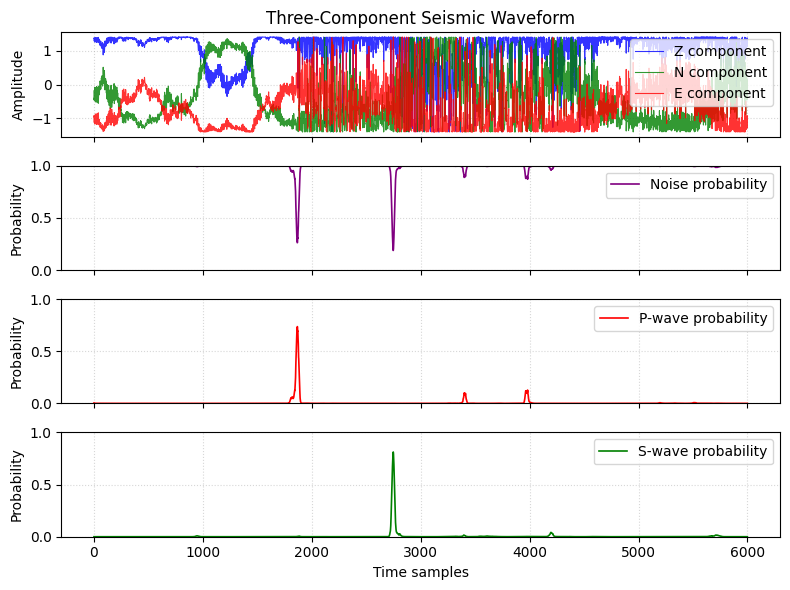

In [5]:


import h5py
import torch
import seisbench.models as sbm
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import resample,butter,filtfilt
def normalize_data(data, mode='std'):
        data = data - np.mean(data, axis=1, keepdims=True)
        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val < 1e-6] = 1.0  # 更稳健地避免除以0或小数
            data = data / std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val < 1e-6] = 1.0
            data = data / max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')

    filtered = np.zeros_like(data)
    padlen = 3 * max(len(b), len(a))

    for ch in range(data.shape[0]):
        if data.shape[1] <= padlen:
            # 太短，跳过滤波，直接返回原始数据
            filtered[ch] = data[ch]
        else:
            filtered[ch] = filtfilt(b, a, data[ch])
    return filtered



# 1. 加载数据（确保正确处理HDF5格式）
f = h5py.File(r'/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/谛听1.0-50HZ/Diting50hz/processed/DiTing330km_part_27_processed.hdf5', 'r')
trace_name ='870743.0098_EV'
ff=f['data']

fd=ff.get(trace_name)[:]

normalized = bandpass_filter(fd, lowcut=1.0, highcut=45.0, fs=100)

# # # 标准化
normalized = normalize_data(normalized, mode='std')


# 2. 准备模型输入
x = torch.from_numpy(normalized.T).unsqueeze(0)  # (1, 3, 6000)
x = x.to(torch.float32)  # 确保使用float32

# 3. 加载并转换模型
model = sbm.PhaseNet.from_pretrained("original").float()  # 关键！将模型转为float32
model.eval()
print(x.shape)
# 4. 执行预测（带sigmoid激活）
with torch.no_grad():
    result = model(x)
    n = result[:,0,:] # 噪声通道
    p = result[:,1,:] # P波通道
    s = result[:,2,:] # S波通道

# 5. 改进的可视化
fig, ax = plt.subplots(4, 1, figsize=(8,6), sharex=True)

# 波形图（Z/N/E分量）
components = ['Z', 'N', 'E']
colors = ['blue', 'green', 'red']
for i in range(3):
    ax[0].plot(x[0, i, :], label=f'{components[i]} component', 
               color=colors[i], linewidth=0.8, alpha=0.8)
ax[0].set_ylabel('Amplitude')
ax[0].legend(loc='upper right')
ax[0].set_title('Three-Component Seismic Waveform')

# 概率图（统一处理）
probabilities = [n, p, s]
labels = ['Noise', 'P-wave', 'S-wave']
colors = ['purple', 'red', 'green']
for i, (prob, label) in enumerate(zip(probabilities, labels), 1):
    ax[i].plot(prob[0], color=colors[i-1], label=f'{label} probability', 
               linewidth=1.2)
    ax[i].set_ylabel('Probability')
    ax[i].set_ylim(0, 1)
    ax[i].legend(loc='upper right')
    if i == 3:
        ax[i].set_xlabel('Time samples')

# 添加网格线
for axis in ax:
    axis.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [24]:
import h5py
import numpy as np
# 1. 加载数据（确保正确处理HDF5格式）
f = h5py.File(r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/waveforms.hdf5', 'r')
trace_name = 'bucket321$246,:3,:6000'
group = trace_name.split('$')[0].strip()
index = int(trace_name.split('$')[1].split(',')[0].strip())
fd = f['data'][group][index, :, :].astype(np.float32)  # 明确指定float32

np.savez('test.npy',data=fd)

# EQtransformer

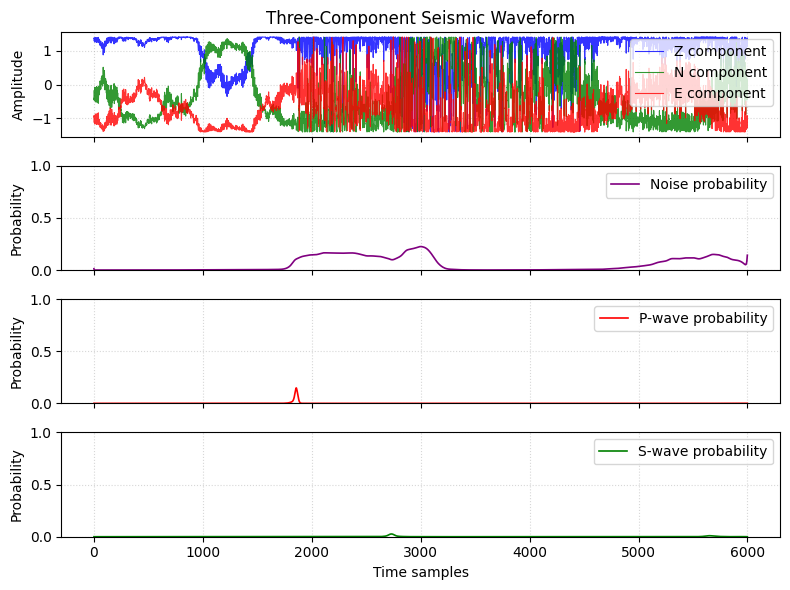

In [9]:
import h5py
import torch
import seisbench.models as sbm
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import resample,butter,filtfilt
def normalize_data(data, mode='std'):
        data = data - np.mean(data, axis=1, keepdims=True)
        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val < 1e-6] = 1.0  # 更稳健地避免除以0或小数
            data = data / std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val < 1e-6] = 1.0
            data = data / max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')

    filtered = np.zeros_like(data)
    padlen = 3 * max(len(b), len(a))

    for ch in range(data.shape[0]):
        if data.shape[1] <= padlen:
            # 太短，跳过滤波，直接返回原始数据
            filtered[ch] = data[ch]
        else:
            filtered[ch] = filtfilt(b, a, data[ch])
    return filtered



# 1. 加载数据（确保正确处理HDF5格式）
f = h5py.File(r'/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/谛听1.0-50HZ/Diting50hz/processed/DiTing330km_part_27_processed.hdf5', 'r')
trace_name ='870743.0098_EV'
ff=f['data']

fd=ff.get(trace_name)[:]

# normalized = bandpass_filter(fd, lowcut=1.0, highcut=45.0, fs=100)

# # # 标准化
normalized = normalize_data(normalized, mode='std')


# 2. 准备模型输入
x = torch.from_numpy(normalized.T).unsqueeze(0)  # (1, 3, 6000)
x = x.to(torch.float32)  # 确保使用float32

# 3. 加载并转换模型
model = sbm.EQTransformer.from_pretrained("original").float()  # 关键！将模型转为float32
model.eval()

# 4. 执行预测（带sigmoid激活）
with torch.no_grad():
    result = model(x)
    n = result[0] # 噪声通道
    p = result[1] # P波通道
    s = result[2] # S波通道

# 5. 改进的可视化
fig, ax = plt.subplots(4, 1, figsize=(8,6), sharex=True)

# 波形图（Z/N/E分量）
components = ['Z', 'N', 'E']
colors = ['blue', 'green', 'red']
for i in range(3):
    ax[0].plot(x[0, i, :], label=f'{components[i]} component', 
               color=colors[i], linewidth=0.8, alpha=0.8)
ax[0].set_ylabel('Amplitude')
ax[0].legend(loc='upper right')
ax[0].set_title('Three-Component Seismic Waveform')

# 概率图（统一处理）
probabilities = [n, p, s]
labels = ['Noise', 'P-wave', 'S-wave']
colors = ['purple', 'red', 'green']
for i, (prob, label) in enumerate(zip(probabilities, labels), 1):
    ax[i].plot(prob[0], color=colors[i-1], label=f'{label} probability', 
               linewidth=1.2)
    ax[i].set_ylabel('Probability')
    ax[i].set_ylim(0, 1)
    ax[i].legend(loc='upper right')
    if i == 3:
        ax[i].set_xlabel('Time samples')

# 添加网格线
for axis in ax:
    axis.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# Moe

输入数据形状: torch.Size([1, 6000, 3])


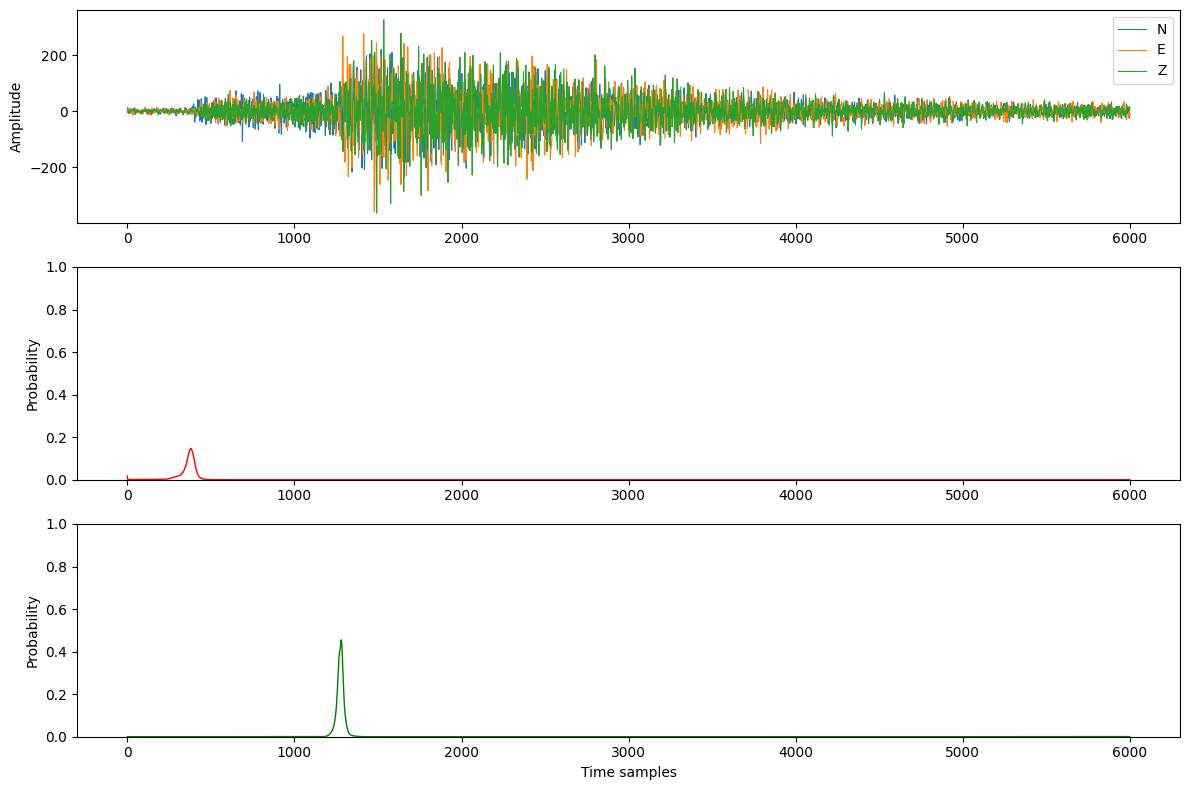

In [37]:
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from torch.utils.data import Dataset, DataLoader
import multiprocessing as mp
from tqdm import tqdm
from model_moe_gpt_PS3_CPU import IMG1

# 配置参数
batch_size = 200
input_csv = "/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/metadata.csv"
hdf5_path = "/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/waveforms.hdf5"
trace_name = name

# 1. 修正数据加载函数
def load_hdf5_data(hdf5_path, trace_name):
    """从HDF5文件中加载指定trace的数据并正确格式化"""
    a = trace_name.split('$')[0].strip()
    c = trace_name.split('$')[1].split(',')[0].strip()
    
    with h5py.File(hdf5_path, 'r') as f:
        ff = f['data']
        # 原始数据形状应为(3, 6000)
        data = ff.get(a)[int(c), :, :].astype(np.float32)  # 确保float32类型
    
    # 转换为PyTorch张量并调整维度顺序
    data = torch.from_numpy(data)  # 形状(3, 6000)
    data = data.permute(1, 0)      # 调整为(6000, 3)以满足模型输入要求
    return data.unsqueeze(0)       # 添加batch维度 -> (1, 6000, 3)

# 2. CPU预测函数
def cpu_predict(model, input_data):
    """使用CPU进行预测"""
    model.eval()
    with torch.no_grad():
        # 确保输入数据在CPU上且为float32
        input_data = input_data.float().cpu()
        output,_ = model(input_data)
        p_prob = output[0].numpy()  # P波概率
        s_prob = output[1].numpy()  # S波概率
    return p_prob, s_prob

# 3. 可视化函数
def plot_results(original_data, p_prob, s_prob):
    """绘制原始波形和预测结果"""
    fig, ax = plt.subplots(3, 1, figsize=(8,6))
    
    # 原始波形 (N, E, Z分量)
    # 注意：需要将数据转回(3, 6000)格式用于绘图
    original_data = original_data.squeeze(0).permute(1, 0)  # (6000,3) -> (3,6000)
    ax[0].plot(original_data[0, :], label="N", linewidth=0.8)
    ax[0].plot(original_data[1, :], label="E", linewidth=0.8)
    ax[0].plot(original_data[2, :], label="Z", linewidth=0.8)
    ax[0].set_ylabel('Amplitude')
    ax[0].legend()
    
    # P波概率
    ax[1].plot(p_prob[0], label="P probability", color='red', linewidth=1)
    ax[1].set_ylabel('Probability')
    ax[1].set_ylim(0, 1)
    
    # S波概率
    ax[2].plot(s_prob[0], label="S probability", color='green', linewidth=1)
    ax[2].set_ylabel('Probability')
    ax[2].set_xlabel('Time samples')
    ax[2].set_ylim(0, 1)
    
    plt.tight_layout()
    plt.show()

# 主流程
if __name__ == "__main__":
    # 强制使用CPU
    device = torch.device('cpu')
    
    # 加载模型 (确保模型在CPU上)
    model = IMG1().to(device)
    model.load_state_dict(
        torch.load(
            "/home/yuan/code/SeisMoE/models/best_model_CPU.pth",
            map_location=device  # 确保加载到CPU
        )
    )
    
    # 加载数据 (注意: 这里不需要转置)
    input_data = load_hdf5_data(hdf5_path, trace_name)
    print(f"输入数据形状: {input_data.shape}")  # 应为(1, 6000, 3)
    
    # 执行预测
    p_prob, s_prob = cpu_predict(model, input_data)
    
    # 可视化结果
    plot_results(input_data, p_prob, s_prob)

In [295]:
import h5py,pandas,numpy
# input_csv = r"/home/cloudlab/意大利数据集instancegm/metadata.csv"
# hdf5_path = r"/home/cloudlab/意大利数据集instancegm/waveforms.hdf5"

input_csv = "/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/metadata.csv"
hdf5_path = "/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/waveforms.hdf5"
csv_data=pd.read_csv(input_csv)
f=h5py.File(hdf5_path,"r")
ff=f['data']

/tmp/ipykernel_1763872/3492393710.py:7: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(input_csv)


In [296]:
csv_data.columns

Index(['trace_coda_end_sample', 'source_depth_km', 'source_latitude_deg',
       'source_longitude_deg', 'source_magnitude', 'source_origin_time',
       'trace_p_arrival_sample', 'trace_p_arrival_time',
       'trace_p_arrival_uncertainty_s', 'trace_s_arrival_sample',
       'trace_s_arrival_time', 'trace_s_arrival_uncertainty_s', 'trace_snr_db',
       'station_elevation_m', 'station_latitude_deg', 'station_longitude_deg',
       'station_code', 'trace_category', 'trace_name_original', 'split',
       'trace_name', 'trace_causal', 'trace_polarity'],
      dtype='object')

In [308]:
trace_name=csv_data['trace_name'][344652]
trace_name
a=trace_name.split('$')[0]
b=trace_name.split('$')[1]
c=b.split(',')[0]
data=ff.get(a)[int(c),:,:]

In [309]:
data.shape

(3, 6000)

In [310]:
print(a,c)

bucket335 869


# predict


In [12]:
import pandas as pd
import numpy as np
import os
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
phasenet=pd.read_csv('/home/cloudlab/Code_DL/DL/model_predict/model_TEST_NEW/STEAD_outputs/X_prediction_results.csv')
stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv')

/tmp/ipykernel_292816/2391798936.py:8: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv')


In [13]:


# 提取 eqt 中的 file_name
file_names = phasenet['file_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]

# 确保时间列是 datetime 格式，使用 errors='coerce' 处理不一致格式
phasenet['p_arrival_time'] = pd.to_datetime(phasenet['p_arrival_time'], errors='coerce')
phasenet['s_arrival_time'] = pd.to_datetime(phasenet['s_arrival_time'], errors='coerce')
# filtered_stead['trace_start_time'] = pd.to_datetime(filtered_stead['trace_start_time'], errors='coerce')


# 确保 trace_start_time 是 datetime 格式
filtered_stead['trace_start_time'] = pd.to_datetime(
    filtered_stead['trace_start_time'],  # 自动解析日期时间
    errors='coerce'  # 无法解析的值会变为 NaT
)


# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='file_name', right_on='trace_name')

merged['p_samples'] = merged['p_arrival_sample']
merged['s_samples'] = merged['s_arrival_sample']
# 计算时间差（向量化操作）
merged['p_time_difference'] = (merged['p_arrival_time'] - merged['trace_start_time']).dt.total_seconds()*100
merged['s_time_difference'] = (merged['s_arrival_time'] - merged['trace_start_time']).dt.total_seconds()*100

merged['p_error']= merged['p_time_difference']-merged['p_samples']
merged['s_error']= merged['s_time_difference']-merged['s_samples']

# 选择需要的列
result = merged[['file_name', 'trace_name', 'p_arrival_time','s_arrival_time', 'trace_start_time', 'p_time_difference','s_time_difference','p_samples','s_samples','p_error','s_error']]
# 将结果保存到 CSV 文件

result

/tmp/ipykernel_292816/4086978878.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_stead['trace_start_time'] = pd.to_datetime(


,file_name,trace_name,p_arrival_time,s_arrival_time,trace_start_time,p_time_difference,s_time_difference,p_samples,s_samples,p_error,s_error
0,KNW.AZ_20160202114043_EV,KNW.AZ_20160202114043_EV,2016-02-02 11:40:49,2016-02-02 11:41:00,2016-02-02 11:40:44,500.0,1600.0,500.0,1608.0,0.0,-8.0
1,NMU.UU_20021105115639_EV,NMU.UU_20021105115639_EV,2002-11-05 11:56:45,2002-11-05 11:57:00,2002-11-05 11:56:40,500.0,2000.0,500.0,1956.0,0.0,44.0
2,B054.PB_20150710002959_EV,B054.PB_20150710002959_EV,2015-07-10 00:30:06,2015-07-10 00:30:09,2015-07-10 00:30:01,500.0,800.0,500.0,872.0,0.0,-72.0
3,GDXB.NC_20150228032404_EV,GDXB.NC_20150228032404_EV,2015-02-28 03:24:09,2015-02-28 03:24:10,2015-02-28 03:24:05,400.0,500.0,398.0,464.0,2.0,36.0
4,MCK.AK_20120805060412_EV,MCK.AK_20120805060412_EV,2012-08-05 06:04:22,2012-08-05 06:04:31,2012-08-05 06:04:13,900.0,1800.0,900.0,1716.5,0.0,83.5
...,...,...,...,...,...,...,...,...,...,...,...
7753,GDXB.NC_20110715000854_EV,GDXB.NC_20110715000854_EV,2011-07-15 00:09:02,2011-07-15 00:09:03,2011-07-15 00:08:55,700.0,800.0,698.0,804.0,2.0,-4.0
7754,B081.PB_20150425025355_EV,B081.PB_20150425025355_EV,2015-04-25 02:54:01,2015-04-25 02:54:03,2015-04-25 02:53:56,500.0,700.0,500.0,732.0,0.0,-32.0
7755,KNK.AK_20120720014609_EV,KNK.AK_20120720014609_EV,2012-07-20 01:46:14,2012-07-20 01:46:29,2012-07-20 01:46:10,400.0,1900.0,397.2,1852.2,2.8,47.8
7756,MWC.CI_20140403170805_EV,MWC.CI_20140403170805_EV,2014-04-03 17:08:15,2014-04-03 17:08:26,2014-04-03 17:08:06,900.0,2000.0,900.0,1959.0,0.0,41.0


In [14]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold = 50
result['p_TP'] = np.where(abs(result['p_error']) <= TP_threshold, 1, 0)
result['s_TP'] = np.where(abs(result['s_error']) <= TP_threshold, 1, 0)
#FN表示大于0.5
result['p_FN'] = np.where(abs(result['p_error']) > TP_threshold, 1, 0)
result['s_FN'] = np.where(abs(result['s_error']) > TP_threshold, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是file_name列的末尾为'_NO'的数量

p_FP_count = result['file_name'].str.endswith('_NO').sum()
s_FP_count = result['file_name'].str.endswith('_NO').sum()

#计算precision，recall，f1
p_TP= result['p_TP'].sum()
s_TP= result['s_TP'].sum()

p_FN= result['p_FN'].sum()
s_FN= result['s_FN'].sum()

# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result['p_TP_mae'] = np.where(result['p_TP'] == 1, result['p_error'], 0)
result['s_TP_mae'] = np.where(result['s_TP'] == 1, result['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result['p_TP_mae'].std() / 100
s_TP_std = result['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

P-TP: 7585
P-FP: 4
P-FN: 169
P-Precision: 0.9994729213335091
P-Recall: 0.9782047975238587
P-F1 Score: 0.988724499771883
P-MAE: 0.011128555042847727
P-STD: 0.0422166705409966
S-TP: 5671
S-FP: 4
S-FN: 2083
S-Precision: 0.999295154185022
S-Recall: 0.7313644570544235
S-F1 Score: 0.8445900662744807
S-MAE: 0.2313284263798272
S-STD: 0.23210274564802252


/tmp/ipykernel_292816/1350285884.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['p_TP'] = np.where(abs(result['p_error']) <= TP_threshold, 1, 0)
/tmp/ipykernel_292816/1350285884.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['s_TP'] = np.where(abs(result['s_error']) <= TP_threshold, 1, 0)
/tmp/ipykernel_292816/1350285884.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the ca

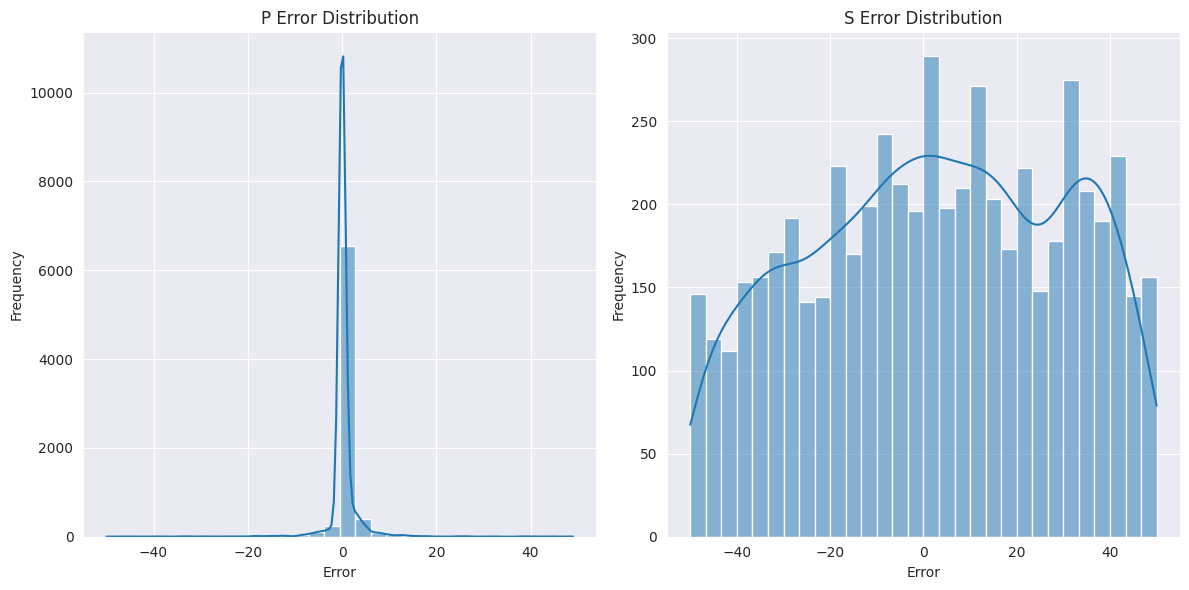

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result[result['p_TP'] == 1]['p_error'], bins=30, kde=True)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result[result['s_TP'] == 1]['s_error'], bins=30, kde=True)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

In [17]:
3709/0.9407-3709

233.8085468268314